# Myocardial infarction — final_final

Three fixed, exploratory analyses only: the previously reproduced rank-3 moment-update analysis;
the best numerically rechecked whole-data Gram candidate; and the best numerically rechecked
unbalanced segmented Gram candidate. “Best” means smallest mean conditional TV to rank 3
in the completed Gram sweep, **not** largest probability of a change. Selection was post hoc.
All use P(0 chgpts)=P(1 chgpt)=1/2 and uniform admissible location conditional on one change.
The same prior determines regression weights. No claim of calibrated change detection is made.

Plot functions and sensitivity-table formatting are copied from the final redo notebook:
LaTeX/serif, black stems, the same figure sizes, tick locations and label sizes. Each analysis
has rho, count probabilities, a conditional posterior, numerical diagnostics and independent
±10%/±20% eigenvalue perturbations. All reported integration calculations use 1024 draws.
For repeated eigenvalues (rank 3), the chosen eigenbasis is conventional, not uniquely identified.
Baseline fits are reproduced; matching archived integration states are reused. New sensitivity
states are checkpointed, with up to 36 workers. No original results are overwritten.

Each analysis has its baseline, diagnostics, achieved Frobenius-norm moment-equation residual, sensitivity study and exports grouped within its own section. Paper-ready PDF/PNG and CSV/LaTeX tables are exported
under `results/myocardial_final_final_v1/paper_assets` in addition to inline display.


The moment diagnostic is $\|\Lambda^T\hat\rho\Lambda+K-S\|_F$, where $S=V_{\mathrm{aux}}^TV_{\mathrm{aux}}/n$. Its relative version divides by $\|S\|_F$. It is distinct from the maximum numerical state-equation residual used in posterior evaluation.

# A. Rank-3 moment-update analysis

This notebook **freshly recomputes the rank-3 experiment** from the raw data,
not from archived fitted coefficients. Uses LS auxiliary fits to estimate rho,
then unpenalized logistic FISTA stopped at **16 iterations** for the posterior;
**no intercept in either stage**. This is intentionally not matched logistic/logistic.

Data: UCI myocardial infarction, binary ZSN>0; remove eight missing-age rows,
sort by age; 110 non-age predictors, mean imputation, centering, covariance-ridge
whitening (1e-6), scale by 1/sqrt(n); n=1692. Delta=2 observations at either end.
The prior is **P(0 chgpts)=P(1 chgpt)=1/2** with uniform location conditional on
one change on the admissible distinct-age grid. The single null configuration
uses signal 0 throughout. Fitting weights are marginals of this same prior.

The LS pilot minimizes split squared error on this grid (including the null).
Starting rho=identity, take **20 damped moment updates**, damping .25,
pseudoinverse cutoff 1e-6, eigenvalue clipping [1e-4,100]. Fits start from zero,
using the package's global-curvature-bounded FISTA step. No explicit penalty.
The residual is reported, not forced to zero.

Posterior states: **1,024 Sobol draws, seed 123**, max100 state-solver
evaluations, order160 likelihood quadrature, 36 parallel jobs. Fresh rho, fitted
scores and baseline posterior must reproduce the saved rank-3 result for this
numerical setting. All reported probabilities and plots use this setting.

Sensitivity: independently scale the two ascending eigenvalues of rho by
.8,.9,1,1.1,1.2 (25 cases), holding eigenvectors, data, fits, prior and all numerical
settings fixed. Re-solve every candidate-specific state, using matched random
draws across perturbations. Use the same 1,024-draw setting throughout. **Conditional
one-change curves sum to one; P(1) includes the null in normalization.**

This is a post-hoc selected heuristic, not a claim of calibrated Bayesian inference.
No attempt is made to force P(1)>1/2. Only plotting style—not the old inconsistent
normalization—is copied from the original final notebook. Checkpoints are unique
and resumable; the original notebooks/results are untouched.


In [1]:
"""Fresh rank-3 reconstruction and paired eigenvalue sensitivity."""
from tools.myocardial_finite_iteration_exploration import *
from itertools import product

ARCHIVE=Path('results/myocardial_finite_iteration_443c17cf2df6/focus_354ed8f1e782')
ARCHIVE_CASE='d2_least_squares_it20_q8_b60'
LEVELS=(.8,.9,1.,1.1,1.2)
CHECKS=((9,42),(10,123))


def perturb_rho(rho, first, second):
    rho=np.asarray(rho,float)
    if first<=0 or second<=0:raise ValueError('positive eigenvalue multipliers required')
    if first==1 and second==1:return rho.copy()
    values,vectors=np.linalg.eigh(rho)
    if values.min()<=0:raise ValueError('positive definite rho required')
    return (vectors*(values*np.array([first,second])))@vectors.T


def normalize_posterior(log_likelihood, prior):
    ll=np.asarray(log_likelihood,float);prior=np.asarray(prior,float)
    if ll.shape!=prior.shape or len(ll)<2 or not np.isfinite(ll).all() or np.any(prior<=0):
        raise ValueError('finite likelihoods and positive aligned prior required')
    np.testing.assert_allclose(prior.sum(),1.,atol=1e-12)
    joint=ll+np.log(prior);q=np.exp(joint-logsumexp(joint))
    conditional=np.exp(joint[1:]-logsumexp(joint[1:]))
    return dict(probabilities=q,conditional=conditional,presence=float(q[1:].sum()),
                absence=float(q[0]),log_likelihood=ll)


def reconstruct():
    X,y,ages,locations=load_data();n,p=X.shape
    eta,prior,phi=configuration_prior(n,locations[(locations>=2)&(locations<=n-2)])
    assert eta[0]==-1
    np.testing.assert_allclose([prior[0],prior[1:].sum()],[.5,.5])
    # The exact rank-3 auxiliary procedure, freshly fitted from raw data.
    B=np.column_stack([np.linalg.lstsq(X*np.sqrt(w[:,None]),y*np.sqrt(w),rcond=None)[0] for w in phi])
    theta=X@B;V,b=empirical_adjustment(theta,y,phi,n/p,loss='squared')
    pilot_eta,psi=pilot(theta,y,eta,'squared');S=V.T@V/n
    rho=np.eye(2);trajectory=[]
    for iteration in range(1,21):
        state=squared_logistic_state(rho,phi,psi,n/p)
        inverse=np.linalg.pinv(state['lambda'],rcond=1e-6)
        rho=project_covariance(.75*rho+.25*project_covariance(inverse.T@(S-state['kappa'])@inverse))
        check=squared_logistic_state(rho,phi,psi,n/p)
        trajectory.append(dict(iteration=iteration,rho=rho.copy(),
            moment_residual=float(np.linalg.norm(check['moment']-S))))
    fitted=finite_fit(X,y,phi,16)
    # Stored results are acceptance checks, never inputs to the new estimates.
    old_setting=pickle.load((ARCHIVE/'fits_delta2.pkl').open('rb'))
    old_rho=next(s['rho'] for s in old_setting['scenarios'] if s['auxiliary']=='least_squares' and s['iteration']==20)
    np.testing.assert_array_equal(eta,old_setting['eta'])
    np.testing.assert_allclose(phi,old_setting['phi'],rtol=0,atol=1e-14)
    np.testing.assert_allclose(rho,old_rho,rtol=1e-9,atol=1e-10)
    np.testing.assert_allclose(fitted['theta'],old_setting['fits']['fista16']['theta'],rtol=1e-9,atol=1e-10)
    np.testing.assert_allclose(fitted['V'],old_setting['fits']['fista16']['V'],rtol=1e-9,atol=1e-10)
    files=('tools/myocardial_final_redo.py','WERM/signal_strength.py','WERM/myocardial_approximate.py',
           'WERM/myocardial_numerics.py','WERM/myocardial_early_stopping.py','WERM/proximal.py',
           'tools/myocardial_exploration.py','results/myocardial_raw_uci579.csv')
    spec=dict(n=n,p=p,Delta=2,fit_budget=16,auxiliary='LS',posterior='unpenalized logistic FISTA',
        intercept=False,rho_updates=20,rho_start='identity',damping=.25,eigenvalue_bounds=[1e-4,100],
        checks=CHECKS,state_max_nfev=100,likelihood_quadrature=160,eigenvalue_levels=LEVELS,
        count_prior=[.5,.5],files={f:hashlib.sha256(Path(f).read_bytes()).hexdigest() for f in files})
    digest=hashlib.sha256(json.dumps(spec,sort_keys=True).encode()).hexdigest()[:12]
    root=Path('results')/('myocardial_final_redo_'+digest);root.mkdir(exist_ok=True)
    (root/'specification.json').write_text(json.dumps(spec,indent=2))
    out=dict(X=X,y=y,ages=ages,eta=eta,prior=prior,phi=phi,rho=rho,fit=fitted,
        trajectory=trajectory,pilot=pilot_eta,root=root,specification=spec)
    atomic_save(root/'fresh_fit_and_rho.pkl',out)
    print('Fresh fits and rho reproduce rank 3. Output:',root,flush=True)
    return out


def location_task(data,levels,power,seed,index):
    root=data['root'];label=f'eig{int(levels[0]*100)}_{int(levels[1]*100)}_q{power}_seed{seed}'
    path=root/f'{label}_location{index}.pkl'
    if path.exists():return pickle.load(path.open('rb'))
    rho=perturb_rho(data['rho'],*levels);y=data['y'];n,p=data['X'].shape;e=data['eta'][index]
    psi=np.zeros(n,int) if e<0 else (np.arange(n)>=e).astype(int)
    import WERM.myocardial_approximate as impl
    old=impl.logistic_prox;impl.logistic_prox=logistic_prox_fast
    try:
        state=impl.logistic_state(rho,data['phi'],psi,n/p,sample_power=power,max_nfev=100,seed=seed)
        ll=gaussian_logistic_loglikelihood(data['fit']['V'],y,rho,state['lambda'],state['kappa'],psi,quadrature_order=160)
    finally:impl.logistic_prox=old
    if not np.isfinite(ll):raise FloatingPointError('nonfinite likelihood')
    record=dict(state=state,log_likelihood=float(ll),index=index,levels=levels,power=power,seed=seed)
    atomic_save(path,record);return record


def compute_scenarios(data,levels_list):
    tasks=[(levels,power,seed,i) for levels in levels_list for power,seed in REPORT_CHECKS for i in range(len(data['eta']))]
    with parallel_config(backend='loky',inner_max_num_threads=1):
        outputs=Parallel(n_jobs=36)(delayed(location_task)(data,*task) for task in tasks)
    records={};k=0
    for levels in levels_list:
        for power,seed in REPORT_CHECKS:
            selected=outputs[k:k+len(data['eta'])];k+=len(data['eta'])
            result=normalize_posterior([r['log_likelihood'] for r in selected],data['prior'])
            result.update(levels=levels,power=power,seed=seed,rho=perturb_rho(data['rho'],*levels),
                ages=data['ages'][data['eta'][1:]],
                residuals=np.array([r['state']['training_residual'] for r in selected]))
            if levels==(1.,1.):
                old=pickle.load((ARCHIVE/f'{ARCHIVE_CASE}_fista16_q{power}_seed{seed}.pkl').open('rb'))
                np.testing.assert_allclose(result['presence'],old['P_1'],rtol=1e-7,atol=1e-8)
                np.testing.assert_allclose(result['conditional'],old['conditional'],rtol=1e-6,atol=1e-8)
            records[(levels,power,seed)]=result
            atomic_save(data['root']/f'scenario_{int(levels[0]*100)}_{int(levels[1]*100)}_q{power}_seed{seed}.pkl',result)
    return records

REPORT_CHECKS=((10,123),)


/scratch/ga442/gab-code-env/papers/WeightedERM-reference/.venv-phase1/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Fresh auxiliary fits and signal-strength estimate

In [2]:
from IPython.display import display
data=reconstruct()
print('rho_hat:');display(pd.DataFrame(data['rho']))
print('Eigenvalues:',np.linalg.eigvalsh(data['rho']))
print('Pilot split observation index:',data['pilot'],'first age after split:',data['ages'][data['pilot']] if data['pilot']>=0 else '0 chgpts')
print('Moment-equation residual:',data['trajectory'][-1]['moment_residual'])
print('Posterior fitting diagnostics:');display(pd.DataFrame(data['fit']['checks']))


Fresh fits and rho reproduce rank 3. Output: results/myocardial_final_redo_e3d965cc4b9b


rho_hat:


,0,1
0,0.003271,0.000000
1,0.000000,0.003271


Eigenvalues: [0.00327089 0.00327089]
Pilot split observation index: 1127 first age after split: 67.0
Moment-equation residual: 0.013166326474434347
Posterior fitting diagnostics:


,kkt,iterations,success,objective,norm
0,0.00019,16,False,0.598510,100.126416
1,0.00018,16,False,0.618138,75.873831


## 2. Probability of 0 versus 1 change point

In [ ]:
records=compute_scenarios(data,[(1.,1.)])
baseline=records[((1.,1.),10,123)]
probability_table=pd.DataFrame([{'Draws':2**power,'Seed':seed,'P(0 chgpts)':r['absence'],
    'P(1 chgpt)':r['presence'],'Max. state residual':r['residuals'].max()}
    for (_,power,seed),r in records.items()])
display(probability_table.style.format({'P(0 chgpts)':'{:.3f}','P(1 chgpt)':'{:.3f}','Max. state residual':'{:.3g}'}))
probability_table.to_csv(data['root']/'baseline_probabilities_1024.csv',index=False)
print('Fresh baseline reproduces the saved 1,024-draw result.')


## 3. Posterior location conditional on 1 change point
Original final notebook stem-plot formatting, applied to normalized conditional probabilities.

The original age-26 stem represented split index 0 (a no-change boundary), which is excluded when conditioning on one change point. Delta=2 also excludes the age-27 split at index 1. No artificial stems are added. Age 26 is the left axis boundary; no artificial stem is added there. Figure size, font settings, label/tick sizes, DPI, and stem/marker styling match the original plotting function.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pickle

# --- 1. Compact Style Setup (JRSSB / Tufte Style) ---
plt.rcParams.update({
    'text.usetex': True,
    'font.family': 'serif',
    'font.serif': ['Times New Roman'],
    'font.size': 14,
    'axes.labelsize': 18, 'axes.titlesize': 18, 'legend.fontsize': 14,
    'axes.linewidth': 1.0,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.dpi': 72,         # High resolution
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})

x_y_labels_fontsize = 18

def plot_posterior_compact(unique_ages, posterior, output_path=None):
    """
    Generates a minimalist stem plot suitable for JRSSB.
    Includes robust NaN handling.
    """
    # --- Data Cleaning ---
    # 1. Flatten to ensuring 1D arrays
    ages = np.array(unique_ages).flatten()
    probs = np.array(posterior).flatten()
    
    # 2. Create a mask to keep only Finite values (removes NaN and Inf)
    # We check both arrays to ensure alignment is preserved
    mask = np.isfinite(ages) & np.isfinite(probs)
    
    # 3. Apply mask
    ages = ages[mask]
    probs = probs[mask]
    
    if len(ages) == 0:
        print("Warning: No valid data points found (all inputs were NaN/Inf).")
        return None, None

    # --- Plotting ---
    fig, ax = plt.subplots(figsize=(12, 2.0))
    
    # JRSSB Style: Black stems, no baseline
    markerline, stemlines, baseline = ax.stem(
        ages, probs,
        linefmt='k-', markerfmt='ko', basefmt=' ', 
    )
    
    # Fine-tune visual elements
    plt.setp(stemlines, linewidth=2.0, alpha=0.8)
    plt.setp(markerline, markersize=4, markeredgewidth=0)

    # --- Smart Ticks ---
    # Find peak (MAP estimate)
    max_idx = np.argmax(probs)
    max_age = ages[max_idx]
    max_prob = probs[max_idx]

    # Calculate integer boundaries safely
    min_age_scalar = int(np.floor(np.min(ages)))
    max_age_scalar = int(np.ceil(np.max(ages)))

    # Generate Decade ticks (e.g. 40, 50, 60...)
    # Ensure start is a multiple of 10
    start_decade = (min_age_scalar // 10 + 1) * 10
    if start_decade < max_age_scalar:
        decades = np.arange(start_decade, max_age_scalar, 10)
    else:
        decades = np.array([])

    # Define critical points (Min, Max, Peak, and 75 as requested)
    critical_points = np.array([min_age_scalar, max_age_scalar, max_age, 75])
    
    # Combine, unique, and sort ticks
    # Filter out ticks that might be outside the valid range due to float/int rounding
    all_ticks = np.unique(np.concatenate((decades, critical_points)))
    all_ticks = all_ticks[(all_ticks >= min_age_scalar) & (all_ticks <= max_age_scalar)]
    
    # ax.set_xticks(all_ticks)
    ax.set_xticks([26, 40, 50, 60, 75, 81, 92]) # Add minor ticks for the original specified ages
    
    # Y-axis: Minimalist (Zero and Peak only)
    ax.set_yticks([0, max_prob])
    ax.set_yticklabels(['0', f'{max_prob:.2f}']) 
    
    ax.tick_params(axis='x', rotation=45, labelsize=14)
    ax.tick_params(axis='y', labelsize=14)

    # --- Labels ---
    ax.set_xlabel(r'Age (years)', fontsize=18)
    # ax.set_ylabel(r'Posterior', fontsize=18)
    ax.grid(axis='y', linestyle=':', color='gray', alpha=0.6)

    if output_path:
        fig.savefig(output_path, bbox_inches='tight', transparent=True)
    
    return fig, ax




fig,ax=plot_posterior_compact(baseline['ages'],baseline['conditional'])
# Restore the previous conditional-plot limits, with age 26 at the left boundary.
ax.set_xlim(26, 95.1)
plt.show()

## 4. Paired ±10% and ±20% eigenvalue sensitivity
The baseline is unchanged. Only the eigenvalues are perturbed; all location-specific states are recomputed.

In [ ]:
remaining=[levels for levels in product(LEVELS,repeat=2) if levels!=(1.,1.)]
records.update(compute_scenarios(data,remaining))
rows=[]
for (levels,power,seed),r in records.items():
    base=records[((1.,1.),power,seed)]
    rows.append({'lambda_1':f'{100*(levels[0]-1):+.0f}%'.replace('+0%','0%'),
        'lambda_2':f'{100*(levels[1]-1):+.0f}%'.replace('+0%','0%'),
        'Draws':2**power,'Seed':seed,'P(0 chgpts)':r['absence'],'P(1 chgpt)':r['presence'],
        'Conditional peak age':r['ages'][np.argmax(r['conditional'])],
        'Conditional mass above 55':r['conditional'][r['ages']>55].sum(),
        'Conditional TV vs baseline':.5*np.abs(r['conditional']-base['conditional']).sum(),
        'Max. state residual':r['residuals'].max()})
summary=pd.DataFrame(rows).sort_values(['Draws','lambda_1','lambda_2'])
np.testing.assert_allclose(summary['P(0 chgpts)']+summary['P(1 chgpt)'],1,atol=1e-12)
summary.to_csv(data['root']/'sensitivity_summary_1024.csv',index=False)
level_order=['-20%','-10%','0%','+10%','+20%']
for power,seed in REPORT_CHECKS:
    print(f'{2**power} draws, seed {seed}: P(1 chgpt)')
    table=summary[summary.Draws==2**power].pivot(index='lambda_1',columns='lambda_2',values='P(1 chgpt)').reindex(index=level_order,columns=level_order)
    display(table.style.format('{:.3f}'))
print('All sensitivity and numerical diagnostics:');display(summary)


## 5. Conditional posterior sensitivity — original panel format, expanded to 5×5

In [ ]:
def plot_sensitivity(field, ylabel):
    fig, axes = plt.subplots(5, 5, figsize=(13*5/3, 7*5/3), sharex=True, sharey=True)
    finite = np.isfinite(ages)
    ymax = max(result[field][finite].max() for result in scenarios.values())
    for row, level_1 in enumerate(level_order):
        for col, level_2 in enumerate(level_order):
            ax = axes[row, col]
            values = scenarios[(level_1, level_2)][field]
            ax.vlines(ages[finite], 0, values[finite], color='black', linewidth=1.1, alpha=0.8)
            ax.plot(ages[finite], values[finite], 'ko', markersize=3)
            ax.set_title(r'$\lambda_1$: '+level_1.replace('%', r'\%')+r', $\lambda_2$: '+level_2.replace('%', r'\%'))
            ax.set_ylim(0, 1.08*ymax)
            ax.set_xticks([26, 40, 60, 81, 92])
            ax.set_yticks([0, ymax])
            ax.set_yticklabels(['0', f'{ymax:.3f}'])
            ax.grid(axis='y', linestyle=':', color='gray', alpha=0.6)
            if row == 4: ax.set_xlabel('Age (years)')
    fig.supylabel(ylabel)
    fig.tight_layout()
    plt.show()


ages=baseline['ages']
for power,seed in REPORT_CHECKS:
    print(f'Conditional on 1 change point: {2**power} draws, seed {seed}')
    scenarios={(level_order[i],level_order[j]):records[((u,v),power,seed)]
        for i,u in enumerate(LEVELS) for j,v in enumerate(LEVELS)}
    plot_sensitivity('conditional','Conditional posterior probability')
print('Completed fresh rank-3 reproduction and sensitivity analysis.')


## Explicit accuracy diagnostics: rho estimation versus posterior numerics

Three distinct quantities must not be conflated: **(i)** the signal-strength
moment-equation mismatch; **(ii)** numerical accuracy of posterior evaluation at
the chosen rho; **(iii)** statistical accuracy/calibration, which is not measured
by either diagnostic. The calculations below use saved fits/states; only the
one-dimensional likelihood quadrature is reevaluated at a finer order.


In [ ]:

import numpy as np
import pandas as pd
import pickle
from IPython.display import display, Markdown
from tools.myocardial_final_redo import (empirical_adjustment, pilot,
    squared_logistic_state, gaussian_logistic_loglikelihood, normalize_posterior)
diagnostic_root=data['root']
X,y,phi=data['X'],data['y'],data['phi']
n,p=X.shape
B_aux=np.column_stack([np.linalg.lstsq(X*np.sqrt(w[:,None]),y*np.sqrt(w),rcond=None)[0] for w in phi])
theta_aux=X@B_aux
V_aux,_=empirical_adjustment(theta_aux,y,phi,n/p,loss='squared')
_,psi_aux=pilot(theta_aux,y,data['eta'],'squared')
observed_moment=V_aux.T@V_aux/n
predicted_moment=squared_logistic_state(data['rho'],phi,psi_aux,n/p)['moment']
rho_residual=np.linalg.norm(predicted_moment-observed_moment,'fro')
relative_rho_residual=rho_residual/np.linalg.norm(observed_moment,'fro')
np.testing.assert_allclose(rho_residual,data['trajectory'][-1]['moment_residual'],rtol=1e-10)
print('Inferred rho_hat (20 updates):')
display(pd.DataFrame(data['rho'],index=['Signal 1','Signal 2'],columns=['Signal 1','Signal 2']).style.format('{:.3f}'))
rho_diagnostics=pd.DataFrame([{
    'Absolute moment residual (Frobenius norm)':rho_residual,
    'Observed moment Frobenius norm':np.linalg.norm(observed_moment,'fro'),
    'Relative moment residual':relative_rho_residual,
    'Last rho update Frobenius norm':np.linalg.norm(data['trajectory'][-1]['rho']-data['trajectory'][-2]['rho']),
    'Smallest rho eigenvalue':np.linalg.eigvalsh(data['rho'])[0]}])
display(rho_diagnostics.T.rename(columns={0:'Value'}).style.format('{:.3g}'))
print('Observed and model-predicted second moments:')
display(pd.DataFrame(observed_moment));display(pd.DataFrame(predicted_moment))
display(Markdown(
    r'The diagnostic is $|\Lambda^T\hat\rho\Lambda+K-S\|_F$, with $S=V_{aux}^TV_{aux}/n$. '
    f'Its value is **{rho_residual:.3f}**, or **{100*relative_rho_residual:.2f}%** of '+
    r'$\|S\|_F$. This is **not** $\|\hat\rho-\rho_{true}\|$, a confidence interval, or a percentage accuracy of rho. '+
    'The true signal strength is unknown. This is a deliberately finite-iteration, constrained heuristic—not a certified moment-equation solution.'))
print('Last five rho updates (moment residual):')
display(pd.DataFrame([{'Update':r['iteration'],'Moment residual':r['moment_residual']} for r in data['trajectory'][-5:]]))
display(Markdown('Both estimated eigenvalues are equal. The ±10%/±20% analysis holds the coordinate eigenbasis fixed; separate eigenvalue perturbations are basis-dependent at this repeated eigenvalue.'))
rho_diagnostics.to_csv(diagnostic_root/'rho_accuracy_diagnostics.csv',index=False)


In [ ]:
residual_value=rho_residual
relative_value=relative_rho_residual

display(Markdown('**Case A: Frobenius-norm moment-equation residual**'))
residual_table=pd.DataFrame([{'Frobenius-norm moment-equation residual':residual_value,
    'Relative Frobenius-norm moment-equation residual':relative_value}])
display(residual_table.T.rename(columns={0:'Value'}).style.format('{:.3g}'))
display(Markdown(f'The achieved Frobenius-norm moment-equation residual is **{residual_value:.3g}**, '
    f'or **{100*relative_value:.2f}%** relative to the empirical moment Frobenius norm. '
    'This is an achieved mismatch after 20 updates, not a prescribed tolerance or an error bound on rho_hat.'))
residual_assets=Path('results/myocardial_final_final_v1/paper_assets')
residual_assets.mkdir(parents=True,exist_ok=True)
residual_table.to_csv(residual_assets/'case_A_moment_residual.csv',index=False)
residual_table.to_latex(residual_assets/'case_A_moment_residual.tex',index=False,float_format='%.3g')


In [ ]:

checks=[pickle.load((diagnostic_root/'scenario_100_100_q10_seed123.pkl').open('rb'))]
reported=checks[0]
numerical_diagnostics=pd.DataFrame([{
    'QMC draws':1024,'Seed':123,
    'P(0 chgpts)':reported['absence'],'P(1 chgpt)':reported['presence'],
    'Max sampled-state equation residual':reported['residuals'].max(),
    'Posterior normalization discrepancy':abs(reported['probabilities'].sum()-1),
    'Conditional normalization discrepancy':abs(reported['conditional'].sum()-1),
    'Conditional posterior mode (age)':reported['ages'][np.argmax(reported['conditional'])]}])
display(numerical_diagnostics.T.rename(columns={0:'Value'}).style.format('{:.3g}'))
display(Markdown(
    'All reported results use **1,024 scrambled-Sobol draws, seed 123**. '
    'The approximately 1e-9 state residual measures agreement with the sampled equations, '
    '**not** integration error, exact population-equation error, or statistical calibration. '
    'A single reported QMC setting does not provide a Monte Carlo standard error or confidence interval.'))
numerical_diagnostics.to_csv(diagnostic_root/'posterior_numerical_diagnostics_1024.csv',index=False)


In [ ]:

# Quadrature-only check: freeze each saved state and double the Gaussian
# quadrature order from 160 to 320. This does NOT refit or re-estimate rho.
quadrature_rows=[]
for (power,seed),baseline_result in zip(((10,123),),checks):
    likelihoods=[]
    for index,e in enumerate(data['eta']):
        state=pickle.load((diagnostic_root/f'eig100_100_q{power}_seed{seed}_location{index}.pkl').open('rb'))['state']
        psi=np.zeros(n,int) if e<0 else (np.arange(n)>=e).astype(int)
        likelihoods.append(gaussian_logistic_loglikelihood(data['fit']['V'],y,data['rho'],
            state['lambda'],state['kappa'],psi,quadrature_order=320))
    refined=normalize_posterior(likelihoods,data['prior'])
    quadrature_rows.append({'QMC draws':2**power,'Seed':seed,
        'P(1), quadrature 160':baseline_result['presence'],
        'P(1), quadrature 320':refined['presence'],
        'Absolute P(1) difference':abs(refined['presence']-baseline_result['presence']),
        'Conditional TV difference':.5*np.abs(refined['conditional']-baseline_result['conditional']).sum(),
        'Max absolute log-likelihood difference':np.max(np.abs(np.asarray(likelihoods)-baseline_result['log_likelihood']))})
quadrature_diagnostics=pd.DataFrame(quadrature_rows)
print('Independent error-source check: likelihood quadrature order 160 versus 320')
display(quadrature_diagnostics.style.format(precision=3))
quadrature_diagnostics.to_csv(diagnostic_root/'likelihood_quadrature_diagnostics_1024.csv',index=False)
display(Markdown(
    '**Bottom line:** report the moment residual and numerical differences separately. '+
    'The quadrature comparison isolates likelihood-integration sensitivity with the 1,024-draw states held fixed; it is not an overall posterior error bound. '+
    'The much larger changes under rho perturbation in the sensitivity section are a separate limitation. '+
    'These diagnostics support transparency and numerical reproducibility, **not a claim of accurate signal-strength estimation or calibrated change-point probabilities**.'))


In [11]:
"""Canonical analyses of two fixed, previously selected Gram candidates."""
from tools.myocardial_gram_comparison import *
from tools.myocardial_final_redo import perturb_rho

GRAM_ARCHIVE=Path('results/myocardial_gram_pair_1ce06b10b4f5')
FINAL_ROOT=Path('results/myocardial_final_final_v1')
LEVELS=(.8,.9,1.,1.1,1.2)
REPORT_CHECKS=((10,123),)


def reconstruct_gram(mode):
    # Fixed selections, not a new search for a favorable posterior probability.
    ident,denominator={'whole':('config283','p'),'segmented':('config189','n')}[mode]
    spec=next(s for s in configurations() if s['id']==ident)
    root=FINAL_ROOT/mode;root.mkdir(parents=True,exist_ok=True)
    X,y,ages,locations=load_data()
    prepared=prepare(spec,X,y,locations,root)
    if 'error' in prepared:raise RuntimeError(prepared['error'])
    B=gram_coefficients(prepared,X,y,mode,root)
    rho=B.T@B/(X.shape[1] if denominator=='p' else len(y))
    archived=pickle.load((GRAM_ARCHIVE/mode/f'{ident}_{denominator}_p10s123.pkl').open('rb'))
    np.testing.assert_allclose(rho,archived['rho'],rtol=1e-8,atol=1e-12)
    np.testing.assert_allclose([prepared['setting']['prior'][0],prepared['setting']['prior'][1:].sum()],[.5,.5])
    data=dict(prepared=prepared,X=X,y=y,ages=ages,rho=rho,root=root,mode=mode,
              ident=ident,denominator=denominator,fit=prepared['posterior'],pilot=prepared['pilot'],
              **prepared['setting'])
    atomic_save(root/'fresh_fit_and_rho.pkl',data)
    (root/'specification.json').write_text(json.dumps(dict(spec=spec,mode=mode,denominator=denominator,
        count_prior=[.5,.5],draws=1024,seed=123,levels=LEVELS,source='selected by mean TV to rank3',
        code_sha256=hashlib.sha256(Path('tools/myocardial_final_final_gram.py').read_bytes()).hexdigest()),indent=2))
    return data


def gram_location(data,levels,index):
    label=f'eig{round(100*levels[0])}_{round(100*levels[1])}_q10_seed123_location{index}'
    path=data['root']/(label+'.pkl')
    if path.exists():return pickle.load(path.open('rb'))
    rho=perturb_rho(data['rho'],*levels)
    e=data['eta'][index];psi=np.zeros(len(data['y']),int) if e<0 else (np.arange(len(data['y']))>=e).astype(int)
    if levels==(1.,1.):
        # Reuse exactly matched, already checked baseline integration states.
        old=GRAM_ARCHIVE/data['mode']/f"{data['ident']}_{data['denominator']}_p10s123_partial.pkl"
        state=pickle.load(old.open('rb'))[index]
    else:state=state_at(data['prepared'],rho,psi,power=10,seed=123,loss='logistic')
    ll=intercept_loglikelihood(data['fit']['V'],data['y'],rho,state,psi,order=160)
    if not np.isfinite(ll):raise FloatingPointError(label)
    result=dict(state=state,log_likelihood=float(ll))
    atomic_save(path,result);return result


def gram_scenarios(data,levels_list):
    tasks=[(levels,i) for levels in levels_list for i in range(len(data['eta']))]
    with parallel_config(backend='loky',inner_max_num_threads=1):
        outputs=Parallel(n_jobs=36)(delayed(gram_location)(data,levels,i) for levels,i in tasks)
    records={};n=len(data['eta'])
    for k,levels in enumerate(levels_list):
        selected=outputs[k*n:(k+1)*n]
        result=normalize_posterior([r['log_likelihood'] for r in selected],data['prior'])
        result.update(ages=data['ages'][data['eta'][1:]],rho=perturb_rho(data['rho'],*levels),
                      residuals=np.array([r['state']['training_residual'] for r in selected]))
        if levels==(1.,1.):
            old=pickle.load((GRAM_ARCHIVE/data['mode']/f"{data['ident']}_{data['denominator']}_p10s123.pkl").open('rb'))
            np.testing.assert_allclose(result['presence'],old['P_1'],atol=1e-7,rtol=1e-7)
            np.testing.assert_allclose(result['conditional'],old['conditional'],atol=1e-7,rtol=1e-6)
        records[(levels,10,123)]=result
        atomic_save(data['root']/f'scenario_{round(100*levels[0])}_{round(100*levels[1])}_q10_seed123.pkl',result)
    return records


def gram_diagnostics(data,baseline):
    prepared=data['prepared'];V=prepared['auxiliary']['V'];observed=V.T@V/len(V)
    state=state_at(prepared,data['rho'],prepared['psi'],power=10,seed=123,loss=prepared['loss'])
    residual=np.linalg.norm(state['moment']-observed,'fro')
    display(pd.DataFrame([{'Frobenius moment-equation residual':residual,
        'Relative moment-equation residual':residual/np.linalg.norm(observed,'fro'),
        'Correlation':data['rho'][0,1]/np.sqrt(np.prod(np.diag(data['rho'])))}]).T.rename(columns={0:'Value'}).style.format('{:.3g}'))
    values=[]
    for i,e in enumerate(data['eta']):
        state=gram_location(data,(1.,1.),i)['state']
        psi=np.zeros(len(V),int) if e<0 else (np.arange(len(V))>=e).astype(int)
        values.append(intercept_loglikelihood(data['fit']['V'],data['y'],data['rho'],state,psi,order=320))
    refined=normalize_posterior(values,data['prior'])
    check=pickle.load((GRAM_ARCHIVE/data['mode']/f"{data['ident']}_{data['denominator']}_p10s42.pkl").open('rb'))
    table=pd.DataFrame([{'QMC draws':1024,'P(1), seed 123':baseline['presence'],'P(1), seed 42':check['P_1'],
        'Conditional TV, seeds':.5*np.abs(check['conditional']-baseline['conditional']).sum(),
        'Max sampled-state equation residual':baseline['residuals'].max(),
        'Absolute P(1) difference, quadrature 160 vs 320':abs(refined['presence']-baseline['presence']),
        'Conditional TV, quadrature':.5*np.abs(refined['conditional']-baseline['conditional']).sum()}])
    table.to_csv(data['root']/'numerical_diagnostics.csv',index=False)
    display(table.T.rename(columns={0:'Value'}).style.format('{:.3g}'))
    print('Gram estimates do not solve the moment equations. These diagnostics are numerical checks, not statistical error bounds or evidence of calibration.')

from IPython.display import display
from itertools import product
assets=FINAL_ROOT/'paper_assets';assets.mkdir(parents=True,exist_ok=True)
gram_data={};gram_records={}


In [ ]:
def plot_sensitivity(field, ylabel):
    fig, axes = plt.subplots(5, 5, figsize=(13*5/3, 7*5/3), sharex=True, sharey=True)
    finite = np.isfinite(ages)
    ymax = max(result[field][finite].max() for result in scenarios.values())
    for row, level_1 in enumerate(level_order):
        for col, level_2 in enumerate(level_order):
            ax = axes[row, col]
            values = scenarios[(level_1, level_2)][field]
            ax.vlines(ages[finite], 0, values[finite], color='black', linewidth=1.1, alpha=0.8)
            ax.plot(ages[finite], values[finite], 'ko', markersize=3)
            ax.set_title(r'$\lambda_1$: '+level_1.replace('%', r'\%')+r', $\lambda_2$: '+level_2.replace('%', r'\%'))
            ax.set_ylim(0, 1.08*ymax)
            ax.set_xticks([26, 40, 60, 81, 92])
            ax.set_yticks([0, ymax])
            ax.set_yticklabels(['0', f'{ymax:.3f}'])
            ax.grid(axis='y', linestyle=':', color='gray', alpha=0.6)
            if row == 4: ax.set_xlabel('Age (years)')
    fig.supylabel(ylabel)
    fig.tight_layout()
    fig.savefig(assets/f'{mode}_sensitivity.pdf',bbox_inches='tight',transparent=True)
    fig.savefig(assets/f'{mode}_sensitivity.png',bbox_inches='tight',dpi=300)
    plt.show()



rank_root=Path('results/myocardial_final_redo_e3d965cc4b9b')
baseline=pickle.load((rank_root/'scenario_100_100_q10_seed123.pkl').open('rb'))
fig,ax=plot_posterior_compact(baseline['ages'],baseline['conditional']);ax.set_xlim(26,95.1)
fig.savefig(assets/'rank3_conditional.pdf',bbox_inches='tight',transparent=True);fig.savefig(assets/'rank3_conditional.png',bbox_inches='tight',dpi=300);plt.close(fig)
mode='rank3';ages=baseline['ages']
scenarios={(level_order[i],level_order[j]):pickle.load((rank_root/f'scenario_{round(100*u)}_{round(100*v)}_q10_seed123.pkl').open('rb')) for i,u in enumerate(LEVELS) for j,v in enumerate(LEVELS)}
plot_sensitivity('conditional','Conditional posterior probability')
for filename in ['baseline_probabilities_1024','sensitivity_summary_1024']:
    t=pd.read_csv(rank_root/(filename+'.csv'));t.to_csv(assets/('rank3_'+filename+'.csv'),index=False);t.to_latex(assets/('rank3_'+filename+'.tex'),index=False,float_format='%.3f')
print('Case A exports complete:',assets)

# B. Whole-data Gram

Exact unpenalized LS auxiliary fits; logistic FISTA, 30 iterations, no explicit penalty; intercepts in both stages; Delta=5. rho=B^T B/p, p=110. Selected config283_p. No moment updates or covariance clipping.

Squared loss uses residual squared (not half squared); weighted-mean losses plus the stated penalty; intercepts are unpenalized and excluded from Gram matrices. Same mean-imputed, centered, whitened global features as A. Gram estimates need not satisfy the signal-strength moment equations.

In [ ]:
mode='whole'
data=reconstruct_gram(mode)
gram_data[mode]=data
print('rho_hat:');display(pd.DataFrame(data['rho']))
print('Eigenvalues:',np.linalg.eigvalsh(data['rho']))
print('Pilot index:',data['pilot'],'first age after split:',data['ages'][data['pilot']])
print('Posterior fitting diagnostics:');display(pd.DataFrame(data['fit']['checks']))
records=gram_scenarios(data,[(1.,1.)]);gram_records[mode]=records
baseline=records[((1.,1.),10,123)]
probability_table=pd.DataFrame([{'Draws':1024,'Seed':123,'P(0 chgpts)':baseline['absence'],'P(1 chgpt)':baseline['presence'],'Max. state residual':baseline['residuals'].max()}])
display(probability_table.style.format({'P(0 chgpts)':'{:.3f}','P(1 chgpt)':'{:.3f}','Max. state residual':'{:.3g}'}))
probability_table.to_csv(assets/f'{mode}_probabilities.csv',index=False)
probability_table.to_latex(assets/f'{mode}_probabilities.tex',index=False,float_format='%.3f')

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pickle

# --- 1. Compact Style Setup (JRSSB / Tufte Style) ---
plt.rcParams.update({
    'text.usetex': True,
    'font.family': 'serif',
    'font.serif': ['Times New Roman'],
    'font.size': 14,
    'axes.labelsize': 18, 'axes.titlesize': 18, 'legend.fontsize': 14,
    'axes.linewidth': 1.0,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.dpi': 72,         # High resolution
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})

x_y_labels_fontsize = 18

def plot_posterior_compact(unique_ages, posterior, output_path=None):
    """
    Generates a minimalist stem plot suitable for JRSSB.
    Includes robust NaN handling.
    """
    # --- Data Cleaning ---
    # 1. Flatten to ensuring 1D arrays
    ages = np.array(unique_ages).flatten()
    probs = np.array(posterior).flatten()
    
    # 2. Create a mask to keep only Finite values (removes NaN and Inf)
    # We check both arrays to ensure alignment is preserved
    mask = np.isfinite(ages) & np.isfinite(probs)
    
    # 3. Apply mask
    ages = ages[mask]
    probs = probs[mask]
    
    if len(ages) == 0:
        print("Warning: No valid data points found (all inputs were NaN/Inf).")
        return None, None

    # --- Plotting ---
    fig, ax = plt.subplots(figsize=(12, 2.0))
    
    # JRSSB Style: Black stems, no baseline
    markerline, stemlines, baseline = ax.stem(
        ages, probs,
        linefmt='k-', markerfmt='ko', basefmt=' ', 
    )
    
    # Fine-tune visual elements
    plt.setp(stemlines, linewidth=2.0, alpha=0.8)
    plt.setp(markerline, markersize=4, markeredgewidth=0)

    # --- Smart Ticks ---
    # Find peak (MAP estimate)
    max_idx = np.argmax(probs)
    max_age = ages[max_idx]
    max_prob = probs[max_idx]

    # Calculate integer boundaries safely
    min_age_scalar = int(np.floor(np.min(ages)))
    max_age_scalar = int(np.ceil(np.max(ages)))

    # Generate Decade ticks (e.g. 40, 50, 60...)
    # Ensure start is a multiple of 10
    start_decade = (min_age_scalar // 10 + 1) * 10
    if start_decade < max_age_scalar:
        decades = np.arange(start_decade, max_age_scalar, 10)
    else:
        decades = np.array([])

    # Define critical points (Min, Max, Peak, and 75 as requested)
    critical_points = np.array([min_age_scalar, max_age_scalar, max_age, 75])
    
    # Combine, unique, and sort ticks
    # Filter out ticks that might be outside the valid range due to float/int rounding
    all_ticks = np.unique(np.concatenate((decades, critical_points)))
    all_ticks = all_ticks[(all_ticks >= min_age_scalar) & (all_ticks <= max_age_scalar)]
    
    # ax.set_xticks(all_ticks)
    ax.set_xticks([26, 40, 50, 60, 75, 81, 92]) # Add minor ticks for the original specified ages
    
    # Y-axis: Minimalist (Zero and Peak only)
    ax.set_yticks([0, max_prob])
    ax.set_yticklabels(['0', f'{max_prob:.2f}']) 
    
    ax.tick_params(axis='x', rotation=45, labelsize=14)
    ax.tick_params(axis='y', labelsize=14)

    # --- Labels ---
    ax.set_xlabel(r'Age (years)', fontsize=18)
    # ax.set_ylabel(r'Posterior', fontsize=18)
    ax.grid(axis='y', linestyle=':', color='gray', alpha=0.6)

    if output_path:
        fig.savefig(output_path, bbox_inches='tight', transparent=True)
    
    return fig, ax




fig,ax=plot_posterior_compact(baseline['ages'],baseline['conditional'])
# Restore the previous conditional-plot limits, with age 26 at the left boundary.
ax.set_xlim(26, 95.1)
fig.savefig(assets/f'{mode}_conditional.pdf',bbox_inches='tight',transparent=True)
fig.savefig(assets/f'{mode}_conditional.png',bbox_inches='tight',dpi=300)
plt.show()

In [15]:
gram_diagnostics(data,baseline)

,Value
Frobenius moment-equation residual,0.007869527
Relative moment-equation residual,0.147373801
Correlation,0.962401615


,Value
QMC draws,1024
"P(1), seed 123",0.285035966
"P(1), seed 42",0.286260364
"Conditional TV, seeds",0.00185054978
Max sampled-state equation residual,7.2252252e-10
"Absolute P(1) difference, quadrature 160 vs 320",1.66533454e-16
"Conditional TV, quadrature",8.43690393e-14


Gram estimates do not solve the moment equations. These diagnostics are numerical checks, not statistical error bounds or evidence of calibration.


In [ ]:
prepared=data['prepared']
V_aux=prepared['auxiliary']['V']
S_aux=V_aux.T@V_aux/len(V_aux)
aux_state=state_at(prepared,data['rho'],prepared['psi'],power=10,seed=123,loss=prepared['loss'])
residual_value=float(np.linalg.norm(aux_state['moment']-S_aux,'fro'))
relative_value=residual_value/np.linalg.norm(S_aux,'fro')

display(Markdown('**Case B: Frobenius-norm moment-equation residual**'))
residual_table=pd.DataFrame([{'Frobenius-norm moment-equation residual':residual_value,
    'Relative Frobenius-norm moment-equation residual':relative_value}])
display(residual_table.T.rename(columns={0:'Value'}).style.format('{:.3g}'))
display(Markdown(f'The achieved Frobenius-norm moment-equation residual is **{residual_value:.3g}**, '
    f'or **{100*relative_value:.2f}%** relative to the empirical moment Frobenius norm. '
    'The Gram estimator is not constructed to solve these moment equations: this is a diagnostic mismatch, not a solver tolerance or an error bound on rho_hat.'))
residual_assets=Path('results/myocardial_final_final_v1/paper_assets')
residual_assets.mkdir(parents=True,exist_ok=True)
residual_table.to_csv(residual_assets/'case_B_moment_residual.csv',index=False)
residual_table.to_latex(residual_assets/'case_B_moment_residual.tex',index=False,float_format='%.3g')


## Whole Gram — paired eigenvalue sensitivity

Independently multiply the ascending eigenvalues by 0.8, 0.9, 1, 1.1 and 1.2. Hold eigenvectors, fits, prior and data fixed; recompute each location-specific posterior state using common integration draws.

In [ ]:
mode='whole'
data=gram_data[mode];records=gram_records[mode];baseline=records[((1.,1.),10,123)]
remaining=[levels for levels in product(LEVELS,repeat=2) if levels!=(1.,1.)]
records.update(gram_scenarios(data,remaining))
rows=[]
for (levels,power,seed),r in records.items():
    base=records[((1.,1.),power,seed)]
    rows.append({'lambda_1':f'{100*(levels[0]-1):+.0f}%'.replace('+0%','0%'),
        'lambda_2':f'{100*(levels[1]-1):+.0f}%'.replace('+0%','0%'),
        'Draws':2**power,'Seed':seed,'P(0 chgpts)':r['absence'],'P(1 chgpt)':r['presence'],
        'Conditional peak age':r['ages'][np.argmax(r['conditional'])],
        'Conditional mass above 55':r['conditional'][r['ages']>55].sum(),
        'Conditional TV vs baseline':.5*np.abs(r['conditional']-base['conditional']).sum(),
        'Max. state residual':r['residuals'].max()})
summary=pd.DataFrame(rows).sort_values(['Draws','lambda_1','lambda_2'])
np.testing.assert_allclose(summary['P(0 chgpts)']+summary['P(1 chgpt)'],1,atol=1e-12)
summary.to_csv(data['root']/'sensitivity_summary_1024.csv',index=False)
level_order=['-20%','-10%','0%','+10%','+20%']
for power,seed in REPORT_CHECKS:
    print(f'{2**power} draws, seed {seed}: P(1 chgpt)')
    table=summary[summary.Draws==2**power].pivot(index='lambda_1',columns='lambda_2',values='P(1 chgpt)').reindex(index=level_order,columns=level_order)
    display(table.style.format('{:.3f}'))
print('All sensitivity and numerical diagnostics:');display(summary)

summary.to_csv(assets/f'{mode}_sensitivity.csv',index=False)
table.to_latex(assets/f'{mode}_sensitivity.tex',float_format='%.3f')

In [ ]:
def plot_sensitivity(field, ylabel):
    fig, axes = plt.subplots(5, 5, figsize=(13*5/3, 7*5/3), sharex=True, sharey=True)
    finite = np.isfinite(ages)
    ymax = max(result[field][finite].max() for result in scenarios.values())
    for row, level_1 in enumerate(level_order):
        for col, level_2 in enumerate(level_order):
            ax = axes[row, col]
            values = scenarios[(level_1, level_2)][field]
            ax.vlines(ages[finite], 0, values[finite], color='black', linewidth=1.1, alpha=0.8)
            ax.plot(ages[finite], values[finite], 'ko', markersize=3)
            ax.set_title(r'$\lambda_1$: '+level_1.replace('%', r'\%')+r', $\lambda_2$: '+level_2.replace('%', r'\%'))
            ax.set_ylim(0, 1.08*ymax)
            ax.set_xticks([26, 40, 60, 81, 92])
            ax.set_yticks([0, ymax])
            ax.set_yticklabels(['0', f'{ymax:.3f}'])
            ax.grid(axis='y', linestyle=':', color='gray', alpha=0.6)
            if row == 4: ax.set_xlabel('Age (years)')
    fig.supylabel(ylabel)
    fig.tight_layout()
    fig.savefig(assets/f'{mode}_sensitivity.pdf',bbox_inches='tight',transparent=True)
    fig.savefig(assets/f'{mode}_sensitivity.png',bbox_inches='tight',dpi=300)
    plt.show()


ages=baseline['ages']
for power,seed in REPORT_CHECKS:
    print(f'Conditional on 1 change point: {2**power} draws, seed {seed}')
    scenarios={(level_order[i],level_order[j]):records[((u,v),power,seed)]
        for i,u in enumerate(LEVELS) for j,v in enumerate(LEVELS)}
    plot_sensitivity('conditional','Conditional posterior probability')



# C. Estimated-segment Gram

LS auxiliary and segment refits with L1 strength 0.0001; logistic posterior with the same L1 strength, convergence-seeking solve; intercepts in both stages; Delta=2. rho=Bseg^T Bseg/n, n=1692. Selected config189_n. Unit within-segment weights (not balanced). Pilot selected by auxiliary loss, including the null; segment fits use its estimated split. No moment updates or covariance clipping.

Squared loss uses residual squared (not half squared); weighted-mean losses plus the stated penalty; intercepts are unpenalized and excluded from Gram matrices. Same mean-imputed, centered, whitened global features as A. Gram estimates need not satisfy the signal-strength moment equations.

In [ ]:
mode='segmented'
data=reconstruct_gram(mode)
gram_data[mode]=data
print('rho_hat:');display(pd.DataFrame(data['rho']))
print('Eigenvalues:',np.linalg.eigvalsh(data['rho']))
print('Pilot index:',data['pilot'],'first age after split:',data['ages'][data['pilot']])
print('Posterior fitting diagnostics:');display(pd.DataFrame(data['fit']['checks']))
records=gram_scenarios(data,[(1.,1.)]);gram_records[mode]=records
baseline=records[((1.,1.),10,123)]
probability_table=pd.DataFrame([{'Draws':1024,'Seed':123,'P(0 chgpts)':baseline['absence'],'P(1 chgpt)':baseline['presence'],'Max. state residual':baseline['residuals'].max()}])
display(probability_table.style.format({'P(0 chgpts)':'{:.3f}','P(1 chgpt)':'{:.3f}','Max. state residual':'{:.3g}'}))
probability_table.to_csv(assets/f'{mode}_probabilities.csv',index=False)
probability_table.to_latex(assets/f'{mode}_probabilities.tex',index=False,float_format='%.3f')

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pickle

# --- 1. Compact Style Setup (JRSSB / Tufte Style) ---
plt.rcParams.update({
    'text.usetex': True,
    'font.family': 'serif',
    'font.serif': ['Times New Roman'],
    'font.size': 14,
    'axes.labelsize': 18, 'axes.titlesize': 18, 'legend.fontsize': 14,
    'axes.linewidth': 1.0,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.dpi': 72,         # High resolution
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})

x_y_labels_fontsize = 18

def plot_posterior_compact(unique_ages, posterior, output_path=None):
    """
    Generates a minimalist stem plot suitable for JRSSB.
    Includes robust NaN handling.
    """
    # --- Data Cleaning ---
    # 1. Flatten to ensuring 1D arrays
    ages = np.array(unique_ages).flatten()
    probs = np.array(posterior).flatten()
    
    # 2. Create a mask to keep only Finite values (removes NaN and Inf)
    # We check both arrays to ensure alignment is preserved
    mask = np.isfinite(ages) & np.isfinite(probs)
    
    # 3. Apply mask
    ages = ages[mask]
    probs = probs[mask]
    
    if len(ages) == 0:
        print("Warning: No valid data points found (all inputs were NaN/Inf).")
        return None, None

    # --- Plotting ---
    fig, ax = plt.subplots(figsize=(12, 2.0))
    
    # JRSSB Style: Black stems, no baseline
    markerline, stemlines, baseline = ax.stem(
        ages, probs,
        linefmt='k-', markerfmt='ko', basefmt=' ', 
    )
    
    # Fine-tune visual elements
    plt.setp(stemlines, linewidth=2.0, alpha=0.8)
    plt.setp(markerline, markersize=4, markeredgewidth=0)

    # --- Smart Ticks ---
    # Find peak (MAP estimate)
    max_idx = np.argmax(probs)
    max_age = ages[max_idx]
    max_prob = probs[max_idx]

    # Calculate integer boundaries safely
    min_age_scalar = int(np.floor(np.min(ages)))
    max_age_scalar = int(np.ceil(np.max(ages)))

    # Generate Decade ticks (e.g. 40, 50, 60...)
    # Ensure start is a multiple of 10
    start_decade = (min_age_scalar // 10 + 1) * 10
    if start_decade < max_age_scalar:
        decades = np.arange(start_decade, max_age_scalar, 10)
    else:
        decades = np.array([])

    # Define critical points (Min, Max, Peak, and 75 as requested)
    critical_points = np.array([min_age_scalar, max_age_scalar, max_age, 75])
    
    # Combine, unique, and sort ticks
    # Filter out ticks that might be outside the valid range due to float/int rounding
    all_ticks = np.unique(np.concatenate((decades, critical_points)))
    all_ticks = all_ticks[(all_ticks >= min_age_scalar) & (all_ticks <= max_age_scalar)]
    
    # ax.set_xticks(all_ticks)
    ax.set_xticks([26, 40, 50, 60, 75, 81, 92]) # Add minor ticks for the original specified ages
    
    # Y-axis: Minimalist (Zero and Peak only)
    ax.set_yticks([0, max_prob])
    ax.set_yticklabels(['0', f'{max_prob:.2f}']) 
    
    ax.tick_params(axis='x', rotation=45, labelsize=14)
    ax.tick_params(axis='y', labelsize=14)

    # --- Labels ---
    ax.set_xlabel(r'Age (years)', fontsize=18)
    # ax.set_ylabel(r'Posterior', fontsize=18)
    ax.grid(axis='y', linestyle=':', color='gray', alpha=0.6)

    if output_path:
        fig.savefig(output_path, bbox_inches='tight', transparent=True)
    
    return fig, ax




fig,ax=plot_posterior_compact(baseline['ages'],baseline['conditional'])
# Restore the previous conditional-plot limits, with age 26 at the left boundary.
ax.set_xlim(26, 95.1)
fig.savefig(assets/f'{mode}_conditional.pdf',bbox_inches='tight',transparent=True)
fig.savefig(assets/f'{mode}_conditional.png',bbox_inches='tight',dpi=300)
plt.show()

In [21]:
gram_diagnostics(data,baseline)

,Value
Frobenius moment-equation residual,0.0170243097
Relative moment-equation residual,0.39087064
Correlation,0.294950946


,Value
QMC draws,1024
"P(1), seed 123",0.252322509
"P(1), seed 42",0.261068571
"Conditional TV, seeds",0.01753784
Max sampled-state equation residual,6.51352261e-10
"Absolute P(1) difference, quadrature 160 vs 320",1.05804254e-13
"Conditional TV, quadrature",1.75663706e-14


Gram estimates do not solve the moment equations. These diagnostics are numerical checks, not statistical error bounds or evidence of calibration.


In [ ]:
prepared=data['prepared']
V_aux=prepared['auxiliary']['V']
S_aux=V_aux.T@V_aux/len(V_aux)
aux_state=state_at(prepared,data['rho'],prepared['psi'],power=10,seed=123,loss=prepared['loss'])
residual_value=float(np.linalg.norm(aux_state['moment']-S_aux,'fro'))
relative_value=residual_value/np.linalg.norm(S_aux,'fro')

display(Markdown('**Case C: Frobenius-norm moment-equation residual**'))
residual_table=pd.DataFrame([{'Frobenius-norm moment-equation residual':residual_value,
    'Relative Frobenius-norm moment-equation residual':relative_value}])
display(residual_table.T.rename(columns={0:'Value'}).style.format('{:.3g}'))
display(Markdown(f'The achieved Frobenius-norm moment-equation residual is **{residual_value:.3g}**, '
    f'or **{100*relative_value:.2f}%** relative to the empirical moment Frobenius norm. '
    'The Gram estimator is not constructed to solve these moment equations: this is a diagnostic mismatch, not a solver tolerance or an error bound on rho_hat.'))
residual_assets=Path('results/myocardial_final_final_v1/paper_assets')
residual_assets.mkdir(parents=True,exist_ok=True)
residual_table.to_csv(residual_assets/'case_C_moment_residual.csv',index=False)
residual_table.to_latex(residual_assets/'case_C_moment_residual.tex',index=False,float_format='%.3g')


## Segmented Gram — paired eigenvalue sensitivity

Independently multiply the ascending eigenvalues by 0.8, 0.9, 1, 1.1 and 1.2. Hold eigenvectors, fits, prior and data fixed; recompute each location-specific posterior state using common integration draws.

In [ ]:
mode='segmented'
data=gram_data[mode];records=gram_records[mode];baseline=records[((1.,1.),10,123)]
remaining=[levels for levels in product(LEVELS,repeat=2) if levels!=(1.,1.)]
records.update(gram_scenarios(data,remaining))
rows=[]
for (levels,power,seed),r in records.items():
    base=records[((1.,1.),power,seed)]
    rows.append({'lambda_1':f'{100*(levels[0]-1):+.0f}%'.replace('+0%','0%'),
        'lambda_2':f'{100*(levels[1]-1):+.0f}%'.replace('+0%','0%'),
        'Draws':2**power,'Seed':seed,'P(0 chgpts)':r['absence'],'P(1 chgpt)':r['presence'],
        'Conditional peak age':r['ages'][np.argmax(r['conditional'])],
        'Conditional mass above 55':r['conditional'][r['ages']>55].sum(),
        'Conditional TV vs baseline':.5*np.abs(r['conditional']-base['conditional']).sum(),
        'Max. state residual':r['residuals'].max()})
summary=pd.DataFrame(rows).sort_values(['Draws','lambda_1','lambda_2'])
np.testing.assert_allclose(summary['P(0 chgpts)']+summary['P(1 chgpt)'],1,atol=1e-12)
summary.to_csv(data['root']/'sensitivity_summary_1024.csv',index=False)
level_order=['-20%','-10%','0%','+10%','+20%']
for power,seed in REPORT_CHECKS:
    print(f'{2**power} draws, seed {seed}: P(1 chgpt)')
    table=summary[summary.Draws==2**power].pivot(index='lambda_1',columns='lambda_2',values='P(1 chgpt)').reindex(index=level_order,columns=level_order)
    display(table.style.format('{:.3f}'))
print('All sensitivity and numerical diagnostics:');display(summary)

summary.to_csv(assets/f'{mode}_sensitivity.csv',index=False)
table.to_latex(assets/f'{mode}_sensitivity.tex',float_format='%.3f')

In [ ]:
def plot_sensitivity(field, ylabel):
    fig, axes = plt.subplots(5, 5, figsize=(13*5/3, 7*5/3), sharex=True, sharey=True)
    finite = np.isfinite(ages)
    ymax = max(result[field][finite].max() for result in scenarios.values())
    for row, level_1 in enumerate(level_order):
        for col, level_2 in enumerate(level_order):
            ax = axes[row, col]
            values = scenarios[(level_1, level_2)][field]
            ax.vlines(ages[finite], 0, values[finite], color='black', linewidth=1.1, alpha=0.8)
            ax.plot(ages[finite], values[finite], 'ko', markersize=3)
            ax.set_title(r'$\lambda_1$: '+level_1.replace('%', r'\%')+r', $\lambda_2$: '+level_2.replace('%', r'\%'))
            ax.set_ylim(0, 1.08*ymax)
            ax.set_xticks([26, 40, 60, 81, 92])
            ax.set_yticks([0, ymax])
            ax.set_yticklabels(['0', f'{ymax:.3f}'])
            ax.grid(axis='y', linestyle=':', color='gray', alpha=0.6)
            if row == 4: ax.set_xlabel('Age (years)')
    fig.supylabel(ylabel)
    fig.tight_layout()
    fig.savefig(assets/f'{mode}_sensitivity.pdf',bbox_inches='tight',transparent=True)
    fig.savefig(assets/f'{mode}_sensitivity.png',bbox_inches='tight',dpi=300)
    plt.show()


ages=baseline['ages']
for power,seed in REPORT_CHECKS:
    print(f'Conditional on 1 change point: {2**power} draws, seed {seed}')
    scenarios={(level_order[i],level_order[j]):records[((u,v),power,seed)]
        for i,u in enumerate(LEVELS) for j,v in enumerate(LEVELS)}
    plot_sensitivity('conditional','Conditional posterior probability')



In [25]:
print('All three grouped canonical analyses and publication exports complete:',assets)

All three grouped canonical analyses and publication exports complete: results/myocardial_final_final_v1/paper_assets


## Updated consistent plots

Plotting reference: **Canonical M1 tighter-layout plots (alpha = 0.3)** in `M1_upsample_final.ipynb`. Error-bar plots use its 5 by 4 inch canvas, 18 pt axis labels and 14 pt ticks; among Hausdorff, count and runtime comparisons, only Runtime displays a legend. These cells load saved results only; the original experiment and plotting cells above are unchanged. Run the setup below, then the desired plotting cell. PDFs and PNGs are saved under `results/consistent_plots_20261102/Myocardial/`.

Line summaries retain their original statistic (quartile-distance bars, or mean ± SE where stated); boxplots use 1.5-IQR whiskers and faint deterministic trial jitter. Histograms follow canonical M1: 12 data-range bins, five-fold bandwidth-selected Gaussian KDE, grey overlay, truth-position ticks, and density range 0–18. These histogram display choices can differ from the older plots; the samples do not change. Empty estimates are omitted from conditional localization and pooled location densities, not assigned zero error. Histograms retain every selected setting and method in one grid, with no three-row or three-column cap: 2.5 inches per column and 2.2 inches per row, matching the reference. Other diagnostic plots retain their compact presentation.

In [1]:
"""Approved publication style; also embedded verbatim in final notebook cells.

Only plotting helpers live here. All data choices and plot calls are visible in
the notebook cells. No fitting, simulation, CV for estimators, or job submission.
Histogram KDE bandwidth CV is the canonical M1 visualization procedure.
"""
from pathlib import Path
import hashlib
import json
import pickle
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, FuncFormatter, NullFormatter
from matplotlib.patches import Patch
from sklearn.neighbors import KernelDensity
from sklearn.model_selection import GridSearchCV
from IPython.display import display, Image

PAPER_WIDTH = 427.64493 / 72.27
PANEL_WIDTH = .49 * PAPER_WIDTH
SCALE = 10.5 / 18
PAPER_STYLE = {
    'text.usetex': True, 'font.family': 'serif',
    'font.serif': ['Computer Modern Roman'], 'font.size': 8.5,
    'axes.labelsize': 10.5, 'axes.titlesize': 10.5,
    'xtick.labelsize': 8.5, 'ytick.labelsize': 8.5, 'legend.fontsize': 8,
    'axes.linewidth': .85, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': False, 'xtick.major.width': .85, 'ytick.major.width': .85,
    'xtick.major.size': 3.5, 'ytick.major.size': 3.5,
    'savefig.bbox': None, 'figure.dpi': 120, 'savefig.dpi': 180,
    'figure.autolayout': False, 'figure.constrained_layout.use': False,
    'legend.frameon': False, 'axes.formatter.useoffset': False,
    'text.latex.preamble': '', 'figure.facecolor': 'white', 'axes.facecolor': 'white',
}

# Reference: M1_upsample_final, "Canonical M1 tighter-layout plots (alpha=0.3)".
# Keep this separate from the compact style used for unrelated diagnostic plots.
CANONICAL_STYLE = {
    **PAPER_STYLE,
    'font.size': 14, 'axes.labelsize': 18, 'axes.titlesize': 18,
    'xtick.labelsize': 14, 'ytick.labelsize': 14, 'legend.fontsize': 14,
    'axes.linewidth': 1.5, 'xtick.major.width': 1.5, 'ytick.major.width': 1.5,
    'xtick.major.size': 6, 'ytick.major.size': 6,
    'legend.frameon': True, 'legend.fancybox': True,
    'legend.edgecolor': 'black', 'legend.framealpha': .95,
    'lines.linewidth': 4, 'lines.markersize': 8,
    'figure.dpi': 72, 'savefig.dpi': 300, 'savefig.pad_inches': .1,
}

METHODS = {
    'McScan': ('McScan', '#AA3377', 'o', '--'),
    'MOSEG': ('MOSEG', '#228833', 's', '-.'),
    'DCDP': ('DCDP', '#EE6677', 'X', '--'),
    'DPDU': ('DPDU', '#4477AA', 'P', ':'),
    'charcoal': ('charcoal', '#336677', 'v', '-.'),
    'GLMBSA-CV': ('GLMBSA', '#E69F00', 'p', ':'),
    'WERM-unp': (r'\textbf{WERM}', 'black', 'D', '-'),
    'WERM-unp-10fold': (r'\textbf{WERM}', 'black', 'D', '-'),
    'WERM-L1-jointCV': (r'\textbf{WERM+L1}', 'black', 'D', '-'),
    'WERM-L1-fullCV-2fold': (r'\textbf{WERM+L1}', 'black', 'D', '-'),
}
SOURCE_HASHES, FIGURE_AUDIT = {}, []
KDE_CACHE = {}

def load_saved(filename):
    path = Path(filename)
    raw = path.read_bytes()  # fail explicitly if a result is missing; no dummy data
    SOURCE_HASHES[str(path)] = hashlib.sha256(raw).hexdigest()
    return pickle.loads(raw)

def clean(values):
    values = np.asarray(values, dtype=float).ravel()
    return values[np.isfinite(values)]

def paper_panel(full=False, height=2.05):
    fig, ax = plt.subplots(figsize=(PAPER_WIDTH if full else PANEL_WIDTH, height))
    fig.subplots_adjust(left=.11 if full else .19, right=.98, bottom=.23, top=.97)
    ax.yaxis.set_major_locator(MaxNLocator(4))
    return fig, ax

def export_plot(fig, name, description=''):
    """Export PDF + embedded PNG, retaining canonical geometry and input hashes."""
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    canonical = getattr(fig, '_canonical_m1', False)
    bounds = fig.get_tightbbox(renderer).padded(.1) if canonical else fig.bbox_inches
    pixels = bounds.transformed(fig.dpi_scale_trans)
    for ax in fig.axes:
        if not ax.get_visible():
            continue
        bbox = ax.get_tightbbox(renderer)
        if bbox is not None:
            assert bbox.x0 >= pixels.x0-2 and bbox.y0 >= pixels.y0-2, (name, 'left/bottom clipping', bbox)
            assert bbox.x1 <= pixels.x1+2 and bbox.y1 <= pixels.y1+2, (name, 'right/top clipping', bbox)
    for text in fig.texts:
        bbox = text.get_window_extent(renderer)
        assert bbox.x0 >= pixels.x0-2 and bbox.y0 >= pixels.y0-2 and bbox.x1 <= pixels.x1+2 and bbox.y1 <= pixels.y1+2, (name, 'figure text clipping')
    fig.savefig(OUTPUT_DIR / f'{name}.pdf', bbox_inches=bounds)
    fig.savefig(OUTPUT_DIR / f'{name}.png', bbox_inches=bounds)
    FIGURE_AUDIT.append(dict(name=name, description=description,
        size_inches=[bounds.width, bounds.height],
        canvas_inches=fig.get_size_inches().tolist(),
        canonical_m1=canonical,
        legends=sum(a.get_legend() is not None for a in fig.axes)+len(fig.legends),
        axes=[dict(bounds=list(a.get_position().bounds), xlabel=a.get_xlabel(),
                   ylabel=a.get_ylabel(), title=a.get_title(), ylim=list(a.get_ylim())) for a in fig.axes]))
    print(description or name)
    display(Image(filename=str(OUTPUT_DIR / f'{name}.png')))
    plt.close(fig)
    (OUTPUT_DIR/'manifest.json').write_text(json.dumps(dict(
        style=PAPER_STYLE, sources=SOURCE_HASHES, figures=FIGURE_AUDIT), indent=2))

def verify_sources():
    for path, digest in SOURCE_HASHES.items():
        assert hashlib.sha256(Path(path).read_bytes()).hexdigest() == digest, path
    print(f'Exported {len(FIGURE_AUDIT)} figures to {OUTPUT_DIR}; saved inputs unchanged.')

def error_series(ax, x, groups, label, color='black', marker='D', ls='-', error='quartile', scale=SCALE):
    xplot, means, low, high = [], [], [], []
    for xx, group in zip(x, groups):
        v = clean(group)
        if not len(v):
            continue
        mean = v.mean()
        if error == 'se':
            lo = hi = v.std(ddof=1)/np.sqrt(len(v)) if len(v)>1 else 0
        else:
            q25, q75 = np.percentile(v, [25,75])
            lo, hi = abs(mean-q25), abs(q75-mean)
        xplot.append(xx); means.append(mean); low.append(lo); high.append(hi)
    ax.errorbar(xplot,means,yerr=[low,high],label=label,color=color,marker=marker,ls=ls,
        linewidth=3.5*scale,markersize=8*scale,capsize=4*scale,capthick=2*scale,
        markeredgewidth=2*scale,markeredgecolor='white',alpha=.8)

def box_group(ax, values, position, color, rng, width=.65, jitter=.19):
    v=clean(values)
    if not len(v):
        return
    bp=ax.boxplot([v],positions=[position],widths=width,patch_artist=True,
        showfliers=False,whis=1.5,autorange=True,manage_ticks=False,
        medianprops=dict(color='black',linewidth=2.3*SCALE,zorder=6),
        boxprops=dict(color='black',linewidth=1.35*SCALE),
        whiskerprops=dict(color='black',linewidth=1.25*SCALE),
        capprops=dict(color='black',linewidth=1.25*SCALE))
    bp['boxes'][0].set(facecolor=color,alpha=.28)
    ax.scatter(position+rng.uniform(-jitter,jitter,len(v)),v,s=3,alpha=.12,
               color=color,linewidths=0,zorder=4)
    q25,med,q75=np.percentile(v,[25,50,75])
    if np.isclose(q25,q75,rtol=1e-10,atol=1e-12*max(1.,np.max(np.abs(v)))):
        ax.plot([position-.43*width,position+.43*width],[med,med],
                color='black',lw=3.4*SCALE,zorder=7)

def histogram_grid(groups, titles, colors, truth, name, row_labels=None,
                   panel_titles=None, density_limit=18):
    """Canonical M1 histogram grid with every selected row and method column.

    groups[row][column] contains pooled fractional change-point estimates.
    Uses the exact M1 12-bin/data-range and five-fold Gaussian-KDE setup.
    The fixed canonical density range is retained; clipped peaks are reported.
    """
    with plt.rc_context(CANONICAL_STYLE):
        rows, cols=len(groups),len(titles)
        assert rows>=1 and cols>=1 and all(len(g)==cols for g in groups)
        fig, axes=plt.subplots(rows,cols,figsize=(2.5*cols,2.2*rows),
            sharex=True,sharey=True,squeeze=False,
            gridspec_kw=dict(wspace=.05,hspace=.55 if panel_titles and rows>1 else .08))
        fig._canonical_m1 = True
        peak=0.
        for row in range(rows):
            for col in range(cols):
                ax=axes[row,col]; values=clean(groups[row][col])
                assert np.all((values>=0)&(values<=1)), 'Histogram expects fractional locations'
                if len(values):
                    hist, edges, _=ax.hist(values,bins=12,alpha=.8,color=colors[col],
                        density=True,edgecolor='white',linewidth=1.0)
                    assert np.isclose(np.sum(hist*np.diff(edges)),1)
                    peak=max(peak,float(hist.max()))
                    if len(values)>6:
                        key=hashlib.sha256(values.tobytes()).hexdigest()
                        if key not in KDE_CACHE:
                            cv=GridSearchCV(KernelDensity(kernel='gaussian'),
                                {'bandwidth':np.logspace(-2,0,50)},cv=5,n_jobs=1)
                            cv.fit(values.reshape(-1,1))
                            x=np.linspace(0,1,200)
                            KDE_CACHE[key]=(x,np.exp(cv.best_estimator_.score_samples(x.reshape(-1,1))))
                        x,y=KDE_CACHE[key]
                        ax.plot(x,y,color='#555555',lw=1.0,ls='-',alpha=.8,zorder=2)
                        ax.fill_between(x,y,color='#999999',alpha=.2,zorder=1)
                        peak=max(peak,float(y.max()))
                else:
                    ax.text(.5,.5,r'\textit{N/A}',transform=ax.transAxes,
                        ha='center',va='center',fontsize=12,alpha=.7)
                for cp in truth:
                    ax.axvline(cp,color='black',ls='--',lw=2,alpha=.9,zorder=10)
                ax.set(xlim=(0,1),ylim=(0,density_limit))
                ax.set_xticks(truth,[f'${cp:.2f}$' for cp in truth])
                ax.set_yticks([0,8,16] if density_limit==18 else [0,density_limit/2,density_limit])
                ax.tick_params(width=1,length=4,labelsize=14)
                for spine in ('left','bottom'):ax.spines[spine].set_linewidth(1)
                if row==0 or panel_titles:
                    ax.set_title(panel_titles[row][col] if panel_titles else titles[col],
                                 fontsize=18,pad=10)
                if col==cols-1 and row_labels:
                    ax.text(1.05,.5,row_labels[row],transform=ax.transAxes,rotation=90,
                        va='center',ha='left',fontsize=18)
        fig.text(.5,.01,'Fractional location',ha='center',va='bottom',fontsize=18)
        fig.text(.07,.5,'Density',va='center',rotation='vertical',fontsize=18)
        fig.tight_layout(rect=[.03,.05,.96,.96])
        # Keep the shared x label clear of tick labels in shorter grids.
        if rows==1:fig.subplots_adjust(bottom=.28,top=.78)
        elif rows==2:fig.subplots_adjust(bottom=.16)
        if peak>density_limit:
            print(f'{name}: maximum density {peak:.2f}; canonical display limit {density_limit} (peaks above this are clipped).')
        export_plot(fig,name,'Change-point location histograms: canonical M1 bins, KDE, ticks and layout.')

def comparison_plots(filename, prefix, methods, min_x=None, m3=False,
                     histogram_stride=3, metrics=('haus','size','runtime'), histograms=True):
    payload=load_saved(filename); results,params=payload['results'],payload['params']
    raw_x=np.asarray(params['kappa_list'] if m3 else params['delta_list'])
    keep=np.flatnonzero(raw_x>=min_x) if min_x is not None else np.arange(len(raw_x))
    x=raw_x[keep]**2 if m3 else raw_x[keep]
    xlabel=r'$\kappa^2$' if m3 else r'$\delta=n/p$'
    truth=np.asarray(params['fractional_chgpt_locations'])
    values={}
    for method in methods:
        sizes=np.asarray(results['size_'+method],float)[keep]
        assert sizes.shape[1]==params['num_trials']
        for metric in metrics:
            v=(np.abs(sizes-len(truth)) if metric=='size_error' else
               np.asarray(results[metric+'_'+method],float)[keep].copy())
            if metric=='haus':v=np.where(sizes>0,v,np.nan)
            if metric=='size_error':v=np.abs(sizes-len(truth))
            values[metric,method]=v
    for metric in metrics:
        ylabel={'haus':r'Hausdorff dist. / $n$','size':'No. change points',
                'runtime':'Runtime (s)','size_error':'Set size error'}[metric]
        for kind in ('line','box'):
            with plt.rc_context(CANONICAL_STYLE if kind=='line' else PAPER_STYLE):
                if kind=='line':
                    fig,ax=plt.subplots(figsize=(5.,4.))
                    fig._canonical_m1 = True
                else:
                    fig,ax=paper_panel()
                rng=np.random.default_rng(42)
                handles=[]
                for j,method in enumerate(methods):
                    label,color,marker,ls=METHODS[method];v=values[metric,method]
                    if kind=='line':
                        error_series(ax,x,v,label,color,marker,ls,scale=1)
                    else:
                        for k,g in enumerate(v):box_group(ax,g,k*(len(methods)+1)+j,color,rng)
                        handles.append(Patch(facecolor=color,alpha=.28,edgecolor='black',label=label))
                if kind=='line':
                    if m3:
                        # Preserve the canonical M3 logarithmic kappa-squared axis.
                        ax.set_xscale('log')
                        ax.set_xticks([10,100,1000],['10','100','1000'])
                        ax.xaxis.set_minor_formatter(NullFormatter())
                    else:
                        ax.set_xticks(x[::2],[f'{xx:g}' for xx in x[::2]])
                else:
                    ax.set_xticks(np.arange(len(x))[::2]*(len(methods)+1)+(len(methods)-1)/2,
                                  [f'{xx:.0f}' if m3 else f'{xx:g}' for xx in x[::2]])
                ax.set(xlabel=xlabel,ylabel=ylabel)
                if metric=='size':
                    ax.axhline(len(truth),color='gray',lw=2.5*(1 if kind=='line' else SCALE),alpha=.8,zorder=0)
                    ax.yaxis.set_major_locator(MaxNLocator(4,integer=True));ax.set_ylim(bottom=-.15)
                    if m3:
                        ax.set_ylim(0,params['L']);ax.set_yticks(np.arange(params['L']+1))
                elif metric=='size_error':ax.yaxis.set_major_locator(MaxNLocator(4,integer=True))
                elif metric=='runtime':ax.set_ylim(bottom=0)
                if metric=='runtime':
                    ax.legend(handles=handles if kind=='box' else None,loc='best',
                              prop={'size':14 if kind=='line' else 8},
                              fancybox=True,framealpha=.4)
                if kind=='line':
                    ax.tick_params(axis='both',which='major',width=1.5,length=6,labelsize=14)
                    ax.spines['top'].set_visible(False);ax.spines['right'].set_visible(False)
                    for spine in ('left','bottom'):ax.spines[spine].set_linewidth(1.5)
                    fig.tight_layout()
                export_plot(fig,f'{prefix}_{metric}_{kind}',
                    f'{prefix}: {ylabel}; '+('mean and absolute distances to quartiles' if kind=='line' else 'boxplots with faint trial jitter'))
    if not histograms:return
    # Preserve all selected settings and methods in one canonical grid.
    row_idx=keep[::histogram_stride]
    keys=list(reversed(methods));groups=[]
    for index in row_idx:
        n=int(params['p']*(params['fixed_delta'] if m3 else raw_x[index]))
        group=[]
        for key in keys:
            parts=[np.asarray(cps).ravel() for i,cps in results['chgpts_'+key] if i==index]
            cp=np.concatenate(parts) if parts else np.array([])
            group.append(cp[cp!=-1]/n)
        groups.append(group)
    histogram_grid(groups,[METHODS[k][0] for k in keys],[METHODS[k][1] for k in keys],truth,
        f'{prefix}_hist',
        [rf'$\kappa^2={raw_x[i]**2:.0f}$' if m3 else rf'$\delta={raw_x[i]:g}$' for i in row_idx])


def simple_summary(groups, x, xlabel, ylabel, name, colors=None, error='quartile',
                   kind='box', labels=None, truth=None, title=None):
    with plt.rc_context(CANONICAL_STYLE if kind=='line' else PAPER_STYLE):
        canonical = kind=='line'
        fig,ax=plt.subplots(figsize=(5.,4.)) if canonical else paper_panel()
        fig._canonical_m1 = canonical
        colors=colors or ['black']*len(x)
        if kind=='line':error_series(ax,x,groups,'',error=error,scale=1)
        else:
            rng=np.random.default_rng(42)
            for xx,g,color in zip(x,groups,colors):box_group(ax,g,xx,color,rng,width=.55,jitter=.16)
        ax.set_xticks(x,labels or [str(xx) for xx in x])
        ax.set(xlabel=xlabel,ylabel=ylabel)
        if truth is not None:ax.axhline(truth,color='gray',lw=2.5*(1 if canonical else SCALE),alpha=.8,zorder=0)
        if title:
            fig.subplots_adjust(top=.86)
            ax.set_title(title,pad=4)
        if ylabel=='No. change points':ax.yaxis.set_major_locator(MaxNLocator(4,integer=True))
        if canonical:
            ax.tick_params(axis='both',which='major',width=1.5,length=6,labelsize=14)
            fig.tight_layout()
        export_plot(fig,name)

OUTPUT_DIR=Path('results/consistent_plots_20261102/Myocardial')


### Case A: rank3 — posterior and sensitivity

rank3 1024 integration draws; P(1 chgpt) = 0.4827190434670559


rank3_conditional_posterior


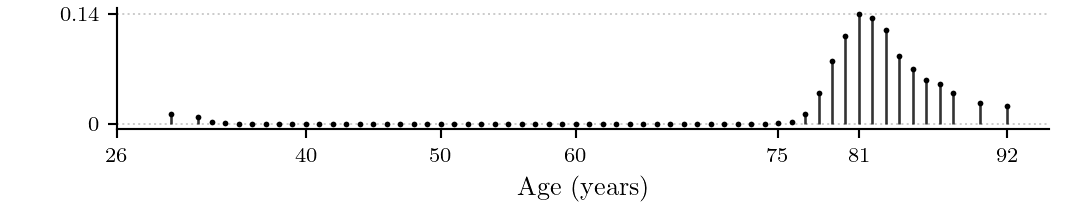

Eigenvalue perturbations; all 25 saved scenarios, 1024 integration draws.


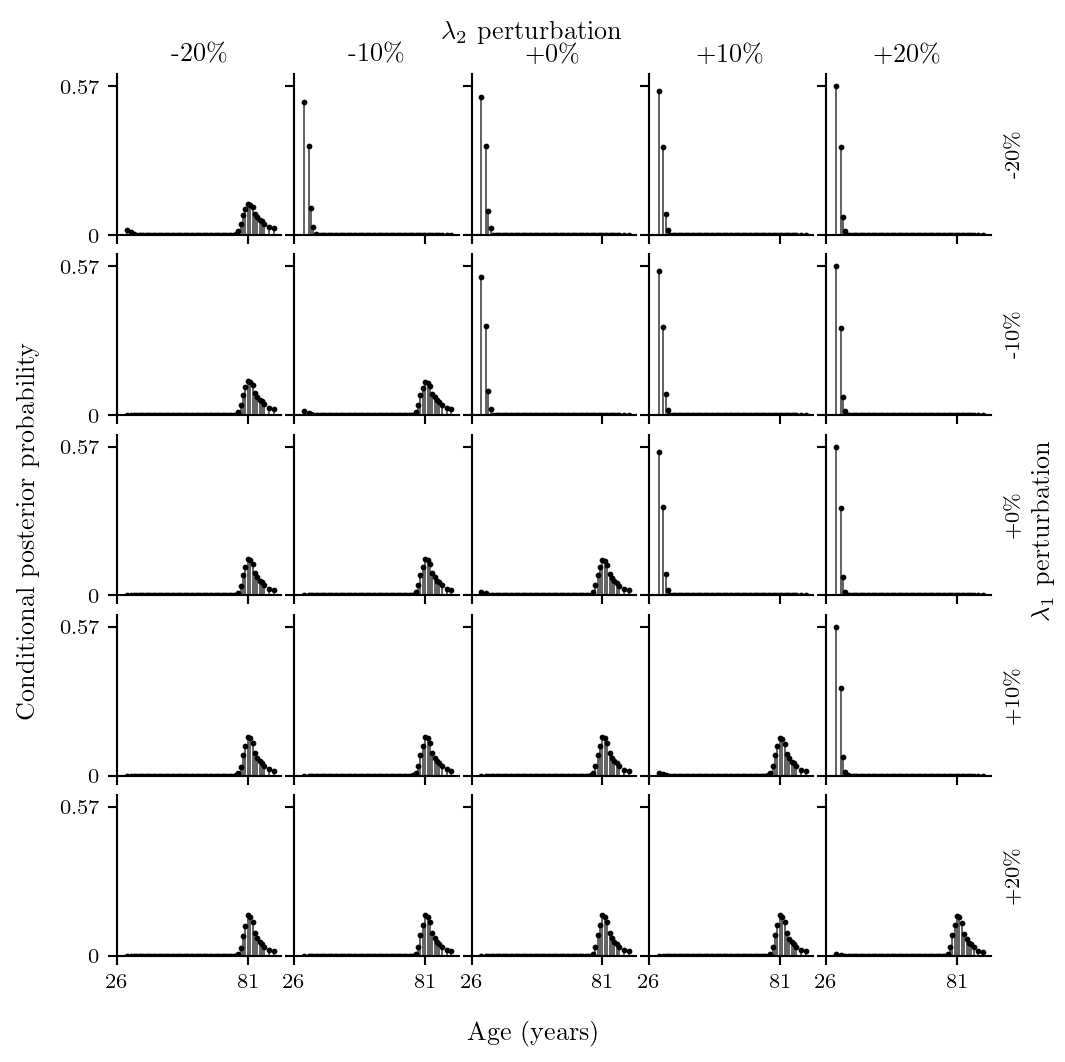

In [2]:
root=Path('results/myocardial_final_redo_e3d965cc4b9b')
mode='rank3'

baseline=load_saved(root/'scenario_100_100_q10_seed123.pkl')
ages=np.asarray(baseline['ages']);prob=np.asarray(baseline['conditional']);finite=np.isfinite(ages)&np.isfinite(prob)
assert np.isclose(prob[finite].sum(),1)
print(mode,'1024 integration draws; P(1 chgpt) =',baseline['presence'])
with plt.rc_context(PAPER_STYLE):
    fig,ax=plt.subplots(figsize=(PAPER_WIDTH,1.18))
    fig.subplots_adjust(left=.11,right=.985,bottom=.39,top=.96)
    markers,stems,_=ax.stem(ages[finite],prob[finite],linefmt='k-',markerfmt='ko',basefmt=' ')
    plt.setp(stems,lw=1.05,alpha=.8);plt.setp(markers,markersize=2.3,markeredgewidth=0)
    ax.set(xlim=(26,95.1),xlabel='Age (years)');ax.set_xticks([26,40,50,60,75,81,92])
    ax.set_yticks([0,max(prob[finite])],['0',f'{max(prob[finite]):.2f}'])
    ax.grid(axis='y',ls=':',color='gray',alpha=.4)
    export_plot(fig,mode+'_conditional_posterior')

    levels=[80,90,100,110,120]
    scenarios={(u,v):load_saved(root/f'scenario_{u}_{v}_q10_seed123.pkl') for u in levels for v in levels}
    maximum=max(np.asarray(s['conditional'])[finite].max() for s in scenarios.values())
    fig,axes=plt.subplots(5,5,figsize=(PAPER_WIDTH,5.9),sharex=True,sharey=True)
    fig.subplots_adjust(left=.11,right=.93,bottom=.10,top=.93,wspace=.08,hspace=.12)
    for i,u in enumerate(levels):
        for j,v in enumerate(levels):
            ax=axes[i,j];values=np.asarray(scenarios[u,v]['conditional'])
            assert np.isclose(values[finite].sum(),1)
            ax.vlines(ages[finite],0,values[finite],color='black',lw=.6,alpha=.8)
            ax.plot(ages[finite],values[finite],'ko',ms=1.3)
            ax.set(xlim=(26,95.1),ylim=(0,1.08*maximum))
            ax.set_xticks([26,81]);ax.set_yticks([0,maximum],['0',f'{maximum:.2f}'])
            if i==0:ax.set_title(f'{v-100:+d}'+r'\%',pad=5)
            if j==4:ax.text(1.08,.5,f'{u-100:+d}'+r'\%',transform=ax.transAxes,rotation=90,va='center')
    fig.text(.5,.98,r'$\lambda_2$ perturbation',ha='center',va='top',fontsize=10.5)
    fig.text(.99,.5,r'$\lambda_1$ perturbation',ha='right',va='center',rotation=90,fontsize=10.5)
    fig.text(.5,.02,'Age (years)',ha='center',fontsize=10.5)
    fig.text(.015,.5,'Conditional posterior probability',rotation=90,va='center',fontsize=10.5)
    export_plot(fig,mode+'_sensitivity','Eigenvalue perturbations; all 25 saved scenarios, 1024 integration draws.')